# FloodVerify: how much cloud or haze is in our val and test tiles?
Runtime: **CPU** (no GPU needed). About 25-30 min including the copy.

Member 4's point: `valid_fraction` only catches black no-data, so cloud and haze count as valid imagery. Before deciding
anything about the evidence contract, measure how big the problem is.

Method: split each 512 px crop into 32x32 px blocks (16 x 16 m at a nominal 0.5 m GSD). A block is **cloud-like** if it
is bright (mean grey level > 200 of 255) and flat (standard deviation < 10). Clouds are bright and featureless; most
ground is darker or textured. This rule WILL also flag white roofs, concrete, sand and sun glint on flood water, so the
numbers are only a screen: section 4 is where you check by eye which flagged crops are really cloud.

Do not commit this notebook with its image outputs to the public repo (xBD imagery may not be redistributed):
clear the outputs of section 4 first.

## 0. Setup

In [2]:
from google.colab import drive
drive.mount("/content/drive")
D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
X, MAN = "/content/xbd", "/content/xbd/rscc_flood_manifest.csv"
!git clone -q https://github.com/aaarrvind/FloodVerify.git /content/FloodVerify 2>/dev/null; echo ok
import sys; sys.path.insert(0, "/content/FloodVerify/src")

Mounted at /content/drive
ok


In [3]:
# Full image copy (10-15 min): Florence and Nepal crops are spread over the official train, test, hold and tier3 folders.
import os
if not os.path.exists(f"{X}/tier3"):
    !mkdir -p /content/xbd
    !tar -xf "{D}/xbd_tars/train_images_labels_targets.tar" -C /content/xbd
    !tar -xf "{D}/xbd_tars/test_images_labels_targets.tar" -C /content/xbd
    !cp -r "{D}/xbd/hold" /content/xbd/
    !cp -r "{D}/xbd/tier3" /content/xbd/
    !cp "{D}/xbd/rscc_flood_manifest.csv" /content/xbd/
!ls /content/xbd
import csv, collections
print(collections.Counter((r["event"], r["split"]) for r in csv.DictReader(open(MAN))
                          if r["event"] in ("hurricane-florence", "nepal-flooding")))

hold  rscc_flood_manifest.csv  test  tier3  train
Counter({('nepal-flooding', 'tier3'): 2476, ('hurricane-florence', 'train'): 1276, ('hurricane-florence', 'hold'): 476, ('hurricane-florence', 'test'): 432})


## 1. The cloud-like score

In [4]:
import numpy as np, pandas as pd
from PIL import Image
from floodsitrep.data.tiling import read_manifest, source_paths, PART_ORIGIN, tile_name
from floodsitrep.data.splits import role_of

BLOCK, BRIGHT, MAX_STD = 32, 200, 10

def cloud_like_fraction(img, valid):
    """Share of mostly-valid 32x32 blocks that are bright and flat. img uint8 HxWx3, valid bool HxW."""
    g = img.astype(np.float32).mean(2)
    h, w = g.shape
    flagged = eligible = 0
    for y in range(0, h, BLOCK):
        for x in range(0, w, BLOCK):
            v = valid[y:y + BLOCK, x:x + BLOCK]
            if v.mean() < 0.5:
                continue
            b = g[y:y + BLOCK, x:x + BLOCK][v]
            eligible += 1
            flagged += (b.mean() > BRIGHT) and (b.std() < MAX_STD)
    return flagged / eligible if eligible else np.nan

# hand check: a white flat square is flagged, random texture is not
img = np.random.default_rng(0).integers(0, 255, (64, 64, 3), dtype=np.uint8); img[:32, :32] = 230
print(cloud_like_fraction(img, np.ones((64, 64), bool)))   # expect 0.25 (1 of 4 blocks)

0.25


## 2. Score every val and test crop (pre and post), one image read per 1024 px tile

In [5]:
rows = [r for r in read_manifest(MAN) if role_of(r["event"]) in ("val", "test")]
groups = {}
for r in rows:
    groups.setdefault((r["split"], r["event"], r["tile_id"]), []).append(r)
out = []
for i, rs in enumerate(groups.values()):
    p = source_paths(X, rs[0])
    pre = np.array(Image.open(p["pre"]).convert("RGB"))
    post = np.array(Image.open(p["post"]).convert("RGB"))
    for r in rs:
        x0, y0 = PART_ORIGIN[r["part"]]
        a, b = pre[y0:y0 + 512, x0:x0 + 512], post[y0:y0 + 512, x0:x0 + 512]
        valid = (a.sum(2) > 0) & (b.sum(2) > 0)
        out.append({"tile": tile_name(r), "event": r["event"], "role": role_of(r["event"]),
                    "valid_fraction": valid.mean(),
                    "cloud_pre": cloud_like_fraction(a, valid), "cloud_post": cloud_like_fraction(b, valid)})
    if i % 200 == 0:
        print(i, "of", len(groups), "images", flush=True)
S = pd.DataFrame(out)
S.to_csv(f"{D}/eval_extras/cloud_screen_val_test.csv", index=False)
print(len(S), "crops scored")

0 of 1165 images
200 of 1165 images
400 of 1165 images
600 of 1165 images
800 of 1165 images
1000 of 1165 images
4660 crops scored


## 3. How many crops are flagged? (screen only: not yet confirmed as cloud)

In [6]:
def share(col, t):
    return S.groupby("event")[col].apply(lambda s: (s > t).mean()).round(3)
pd.DataFrame({"crops": S.groupby("event").size(),
              "post >10% blocks": share("cloud_post", 0.10), "post >50% blocks": share("cloud_post", 0.50),
              "pre >10% blocks": share("cloud_pre", 0.10), "pre >50% blocks": share("cloud_pre", 0.50)})

,crops,post >10% blocks,post >50% blocks,pre >10% blocks,pre >50% blocks
event,,,,,
hurricane-florence,2184,0.008,0.0,0.001,0.0
nepal-flooding,2476,0.003,0.0,0.000,0.0


## 4. Look at the 24 most-flagged crops (post image, with pre for comparison)
For each one decide: **cloud**, **haze**, or **not cloud** (white roofs, concrete, sand, water glint...).
Count them and paste the counts in the chat. Clear this cell's output before committing the notebook anywhere public.

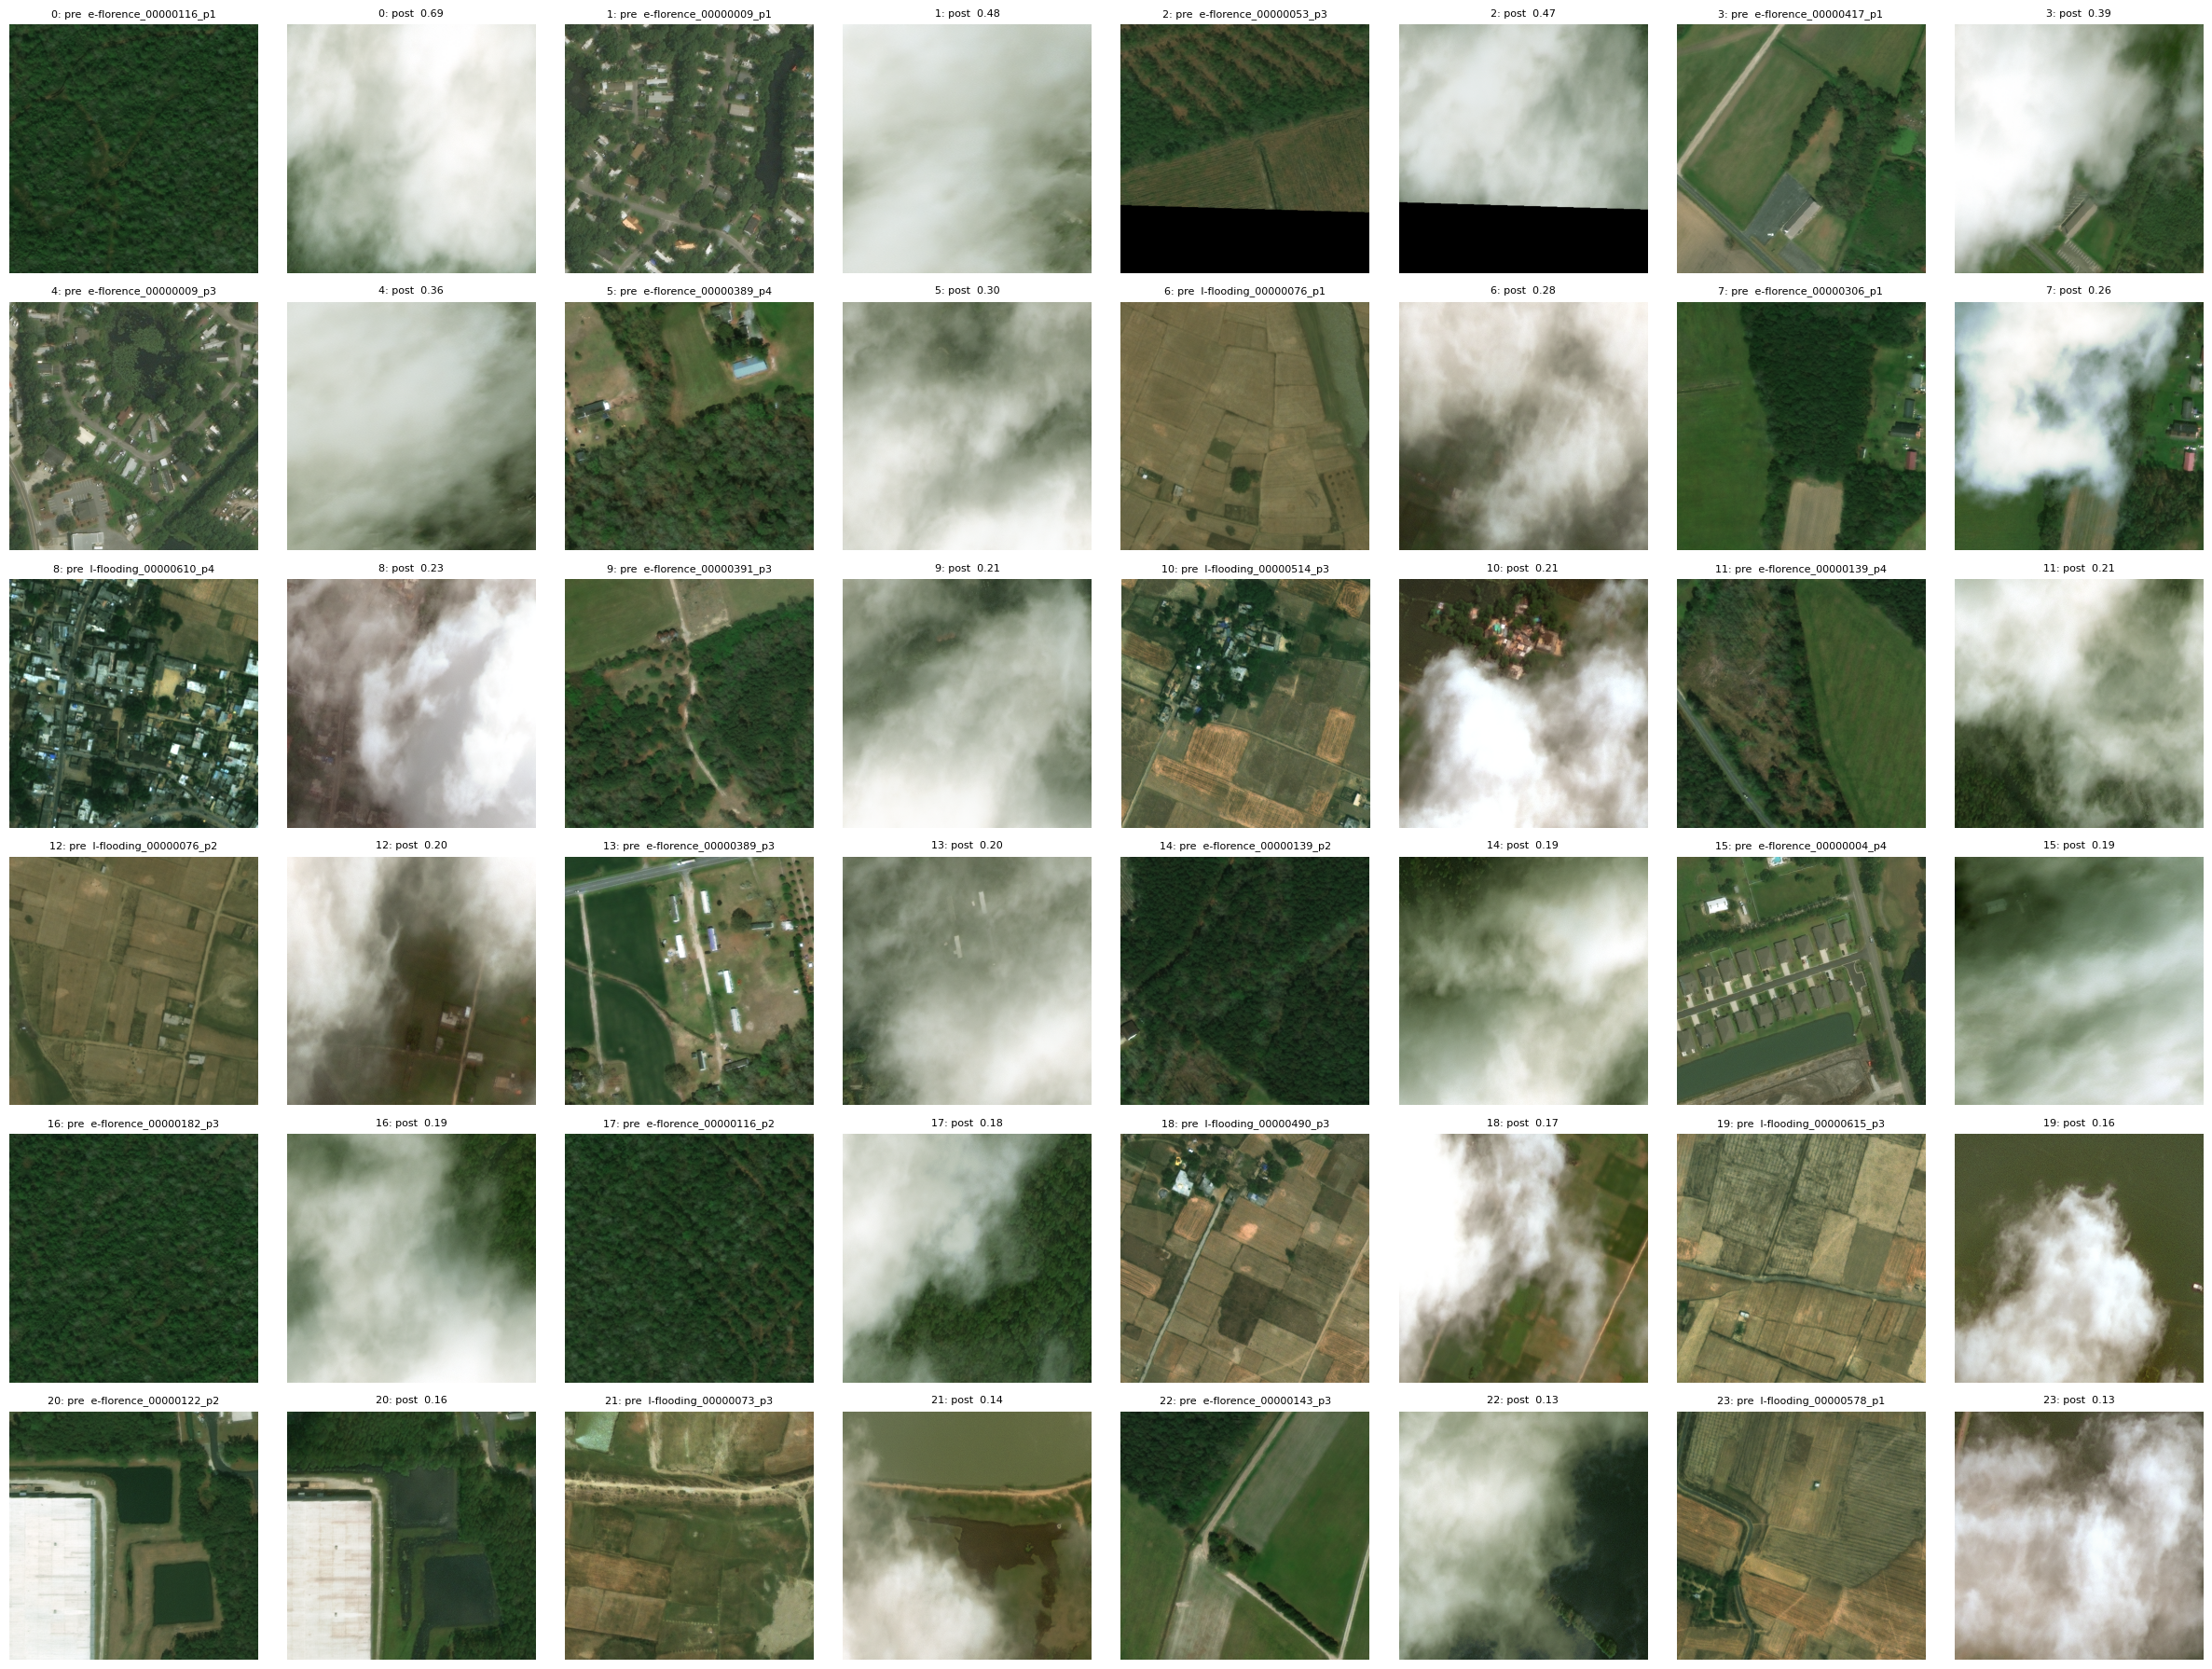

                              tile  cloud_post  cloud_pre  valid_fraction
0   hurricane-florence_00000116_p1       0.691      0.000           1.000
1   hurricane-florence_00000009_p1       0.480      0.000           1.000
2   hurricane-florence_00000053_p3       0.474      0.000           0.729
3   hurricane-florence_00000417_p1       0.395      0.000           1.000
4   hurricane-florence_00000009_p3       0.359      0.000           1.000
5   hurricane-florence_00000389_p4       0.301      0.000           1.000
6       nepal-flooding_00000076_p1       0.277      0.000           1.000
7   hurricane-florence_00000306_p1       0.258      0.000           1.000
8       nepal-flooding_00000610_p4       0.230      0.000           1.000
9   hurricane-florence_00000391_p3       0.211      0.000           1.000
10      nepal-flooding_00000514_p3       0.211      0.000           1.000
11  hurricane-florence_00000139_p4       0.207      0.000           1.000
12      nepal-flooding_00000076_p2    

In [7]:
import matplotlib.pyplot as plt
top = S.sort_values("cloud_post", ascending=False).head(24).reset_index(drop=True)
fig, ax = plt.subplots(6, 8, figsize=(24, 18))
for k, r in top.iterrows():
    event, tid, part = r.tile.rsplit("_", 2)
    row = next(x for x in rows if tile_name(x) == r.tile)
    p = source_paths(X, row); x0, y0 = PART_ORIGIN[row["part"]]
    for j, key in enumerate(("pre", "post")):
        im = np.array(Image.open(p[key]).convert("RGB"))[y0:y0 + 512, x0:x0 + 512]
        a = ax[k // 4, (k % 4) * 2 + j]
        a.imshow(im); a.axis("off")
        a.set_title(f"{k}: {key}  " + (f"{r.cloud_post:.2f}" if key == "post" else r.tile[-22:]), fontsize=8)
plt.tight_layout(); plt.show()
print(top[["tile", "cloud_post", "cloud_pre", "valid_fraction"]].round(3).to_string())

## Done: stop the runtime

In [8]:
from google.colab import runtime
runtime.unassign()